## Упражнения

- Загрузите два временных ряда `arma_ts1` и `arma_ts2`, выполнив код ниже.

In [1]:
import sys

if 'google.colab' in sys.modules:
    !pip install -U -qq tsa-course

In [3]:
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.simplefilter('ignore', ConvergenceWarning)
import requests
from io import BytesIO
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
from statsmodels.tsa.stattools import ccf, adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.arima_process import arma_generate_sample
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from tsa_course.lecture2 import run_sequence_plot
from statsmodels.tsa.ar_model import AutoReg
np.random.seed(0)

In [4]:
# метод вывода графиков
def run_sequence_plot(x, y, title, xlabel="Time", ylabel="Values", ax=None):
    if ax is None:
        _, ax = plt.subplots(1,1, figsize=(10, 3.5))
    ax.plot(x, y, 'k-')
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)
    return ax

In [5]:
# загрузка 1-ого датасета
response = requests.get("https://zenodo.org/records/10951538/files/arma_ts3.npz?download=1")
response.raise_for_status()
arma_ts1 = np.load(BytesIO(response.content))['signal']
print(len(arma_ts1))

# загрузка 2-ого датасета
response = requests.get("https://zenodo.org/records/10951538/files/arma_ts4.npz?download=1")
response.raise_for_status()
arma_ts2 = np.load(BytesIO(response.content))['signal']
print(len(arma_ts2))

479
1000


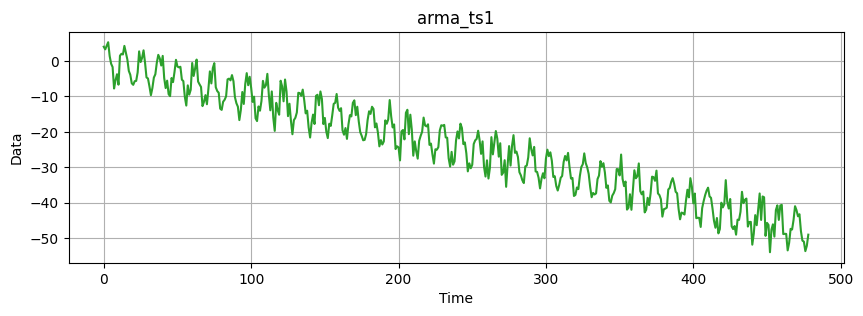

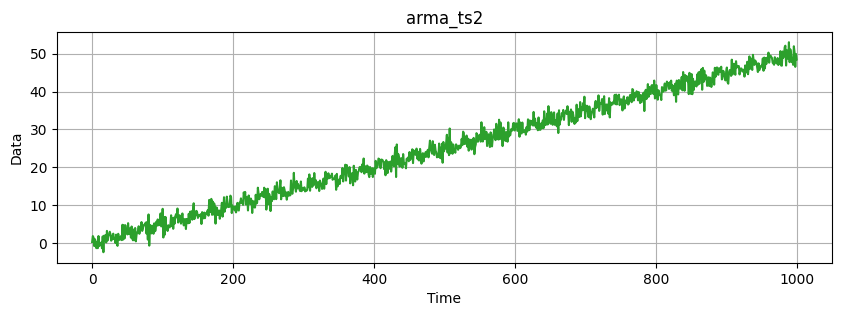

In [6]:
fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(arma_ts1)), arma_ts1, color='tab:green')
ax.set_xlabel("Time")
ax.set_ylabel("Data")
plt.title("arma_ts1");
plt.grid()

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(arma_ts2)), arma_ts2, color='tab:green')
ax.set_xlabel("Time")
ax.set_ylabel("Data")
plt.title("arma_ts2");
plt.grid()

Для каждого временного ряда:

1. Разделите временной ряд на обучающий и тестовый.
    - Используйте последние 30 значений в качестве тестовых для первого временного ряда.
    - Используйте последние 100 значений в качестве тестовых для второго временного ряда.
2. Сделайте временной ряд стационарным.
3. Определите порядок $p$ модели AR.
4. Вычислите прогноз тестовых данных с помощью модели AR($p$).
5. Определите порядок $q$ модели MA.
6. Вычислите прогноз тестовых данных с помощью модели MA($q$).

In [7]:
mytime1 = np.arange(len(arma_ts1))

# обучающий и тестовый наборы для smoothing_ts1
train_ts1 = arma_ts1[:-30]
test_ts1 = arma_ts1[len(arma_ts1)-30:]
mytime1_train = mytime1[:-30]
mytime1_test = mytime1[len(arma_ts1)-30:]

p-value: 0.000


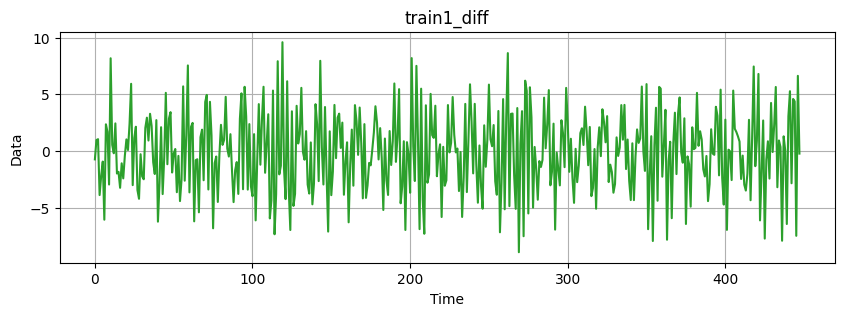

In [8]:
train1_diff = np.diff(train_ts1)

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(train1_diff)), train1_diff, color='tab:green')
ax.set_xlabel("Time")
ax.set_ylabel("Data")
plt.title("train1_diff");
plt.grid()

_, pvalue, _, _, _, _ = adfuller(train1_diff)
print(f"p-value: {pvalue:.3f}")

После дифференцирования ряд стал стационарным.

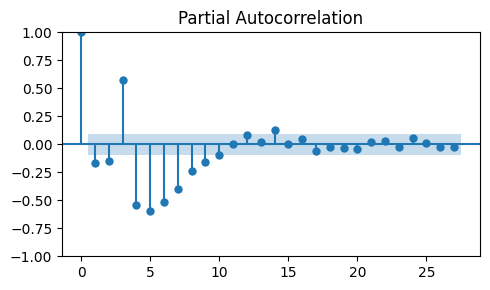

In [9]:
_, ax = plt.subplots(1, 1, figsize=(5, 3))
plot_pacf(train1_diff, ax=ax)
plt.tight_layout();

PACF показывает много значимых лагов, поэтому будет использоваться метод TES.

In [11]:
from scipy.fft import fft

def fft_analysis(signal):
    slope, intercept = np.polyfit(np.arange(len(signal)), signal, 1)
    trend = np.arange(len(signal)) * slope + intercept
    detrended = signal - trend
    fft_values = fft(detrended)
    frequencies = np.fft.fftfreq(len(fft_values))
    positive_frequencies = frequencies[frequencies > 0]
    magnitudes = np.abs(fft_values)[frequencies > 0]
    dominant_frequency = positive_frequencies[np.argmax(magnitudes)]
    print(f"Dominant Frequency: {dominant_frequency:.3f}")
    dominant_period = 1 / dominant_frequency
    print(f"Dominant Period: {dominant_period:.2f} time units")
    return dominant_period, positive_frequencies, magnitudes

period, _, _ =fft_analysis(arma_ts1)
print(f"Period: {np.round(period)}")

Dominant Frequency: 0.084
Dominant Period: 11.97 time units
Period: 12.0


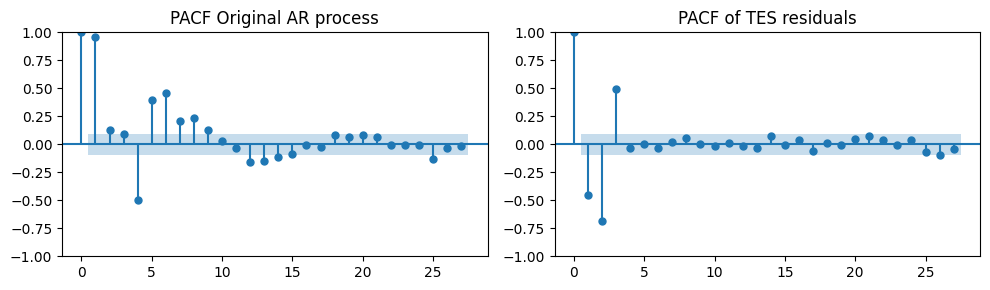

In [13]:
tes = ExponentialSmoothing(
    train_ts1,
    trend='add',
    seasonal='add',
    seasonal_periods=12
    ).fit()

trend_and_seasonality = tes.fittedvalues
tes_resid = train_ts1 - trend_and_seasonality

_, axes = plt.subplots(1, 2, figsize=(10, 3))
plot_pacf(arma_ts1[:len(train_ts1)], ax=axes[0], title="PACF Original AR process")
plot_pacf(tes_resid, ax=axes[1], title="PACF of TES residuals")
plt.tight_layout();

TES показал 3 значимых лага, после которых заметен сильный спад до довертильного интервала, это указывает на авторегрессию. Будет построена модель AR(3).

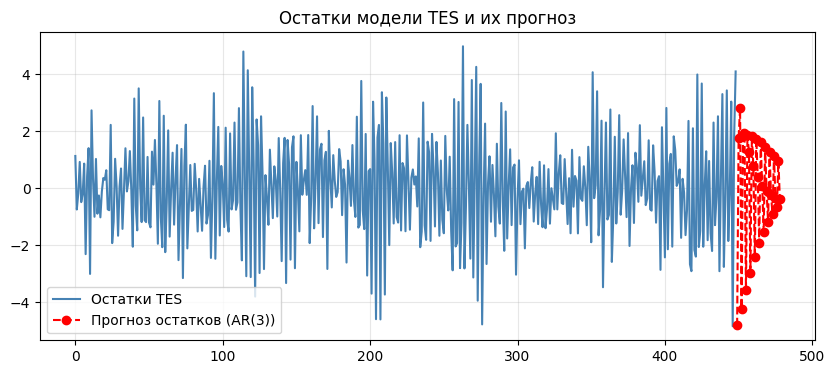

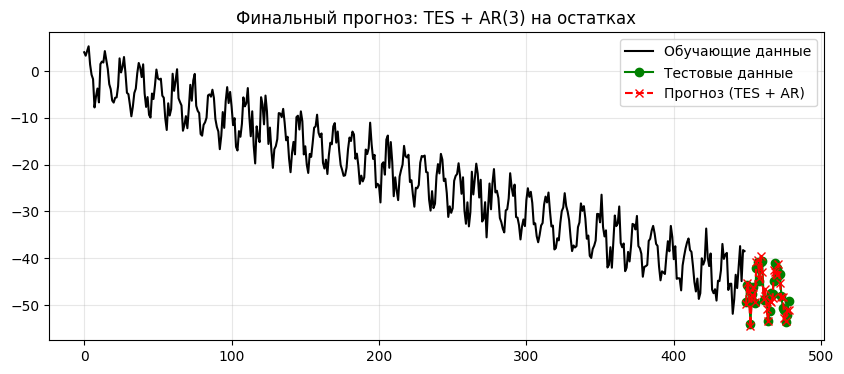

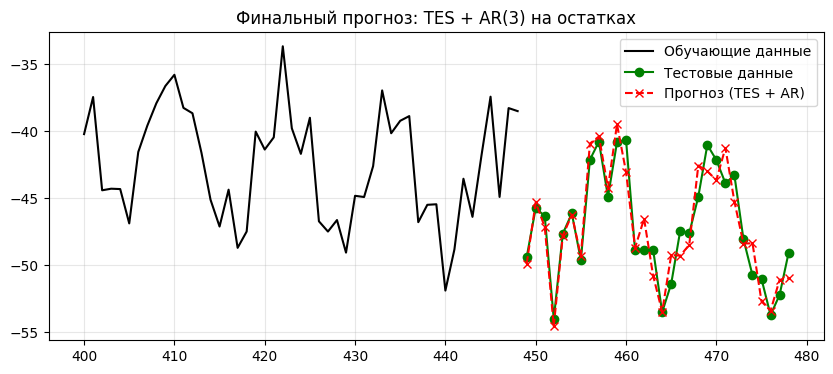

MSE of differencing: 64.20
MSE of TES:          2.16

 Подход на основе TES даёт более точный прогноз!


In [19]:
n1_test = 30

# подгонка TES к обучающим данным
tes = ExponentialSmoothing(
  train_ts1,
  trend='add',
  seasonal='add',
  seasonal_periods=12 # данный период был рассчитан методом
  ).fit()

# остатки
tes_fitted = tes.fittedvalues
tes_resid = train_ts1 - tes_fitted

# модель AR(3) на остатках
ar_model = ARIMA(tes_resid, order=(3, 0, 0))
ar_fit = ar_model.fit()
resid_preds = ar_fit.forecast(steps=n1_test)

# прогноз TES: тренд + сезонность
tes_pred = tes.forecast(steps=n1_test)

# прогноз: TES + AR(остатки)
final_preds_tes = tes_pred + resid_preds

# подход на основе дифференцирования (для сравнения)
diff_train = np.diff(train_ts1)
ar_diff_model = ARIMA(diff_train, order=(3, 0, 0), trend='n').fit()
diff_forecast = ar_diff_model.forecast(steps=n1_test)

# реконструкция уровня (без дрейфа)
reintegrated = np.empty(n1_test)
current = train_ts1[-1]
for i in range(n1_test):
  current = current + diff_forecast[i]
  reintegrated[i] = current

# визуализация остатков
plt.figure(figsize=(10, 4))
plt.plot(mytime1_train, tes_resid, label='Остатки TES', color='steelblue')
plt.plot(mytime1_test, resid_preds, 'ro--', label='Прогноз остатков (AR(3))')
plt.title('Остатки модели TES и их прогноз')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# финальный прогноз (TES + AR)
plt.figure(figsize=(10, 4))
plt.plot(mytime1_train, train_ts1, label='Обучающие данные', color='black')
plt.plot(mytime1_test, test_ts1, 'o-', label='Тестовые данные', color='green')
plt.plot(mytime1_test, final_preds_tes, 'x--', label='Прогноз (TES + AR)', color='red')
plt.title('Финальный прогноз: TES + AR(3) на остатках')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# финальный прогноз (TES + AR)
plt.figure(figsize=(10, 4))
plt.plot(mytime1_train[400:], train_ts1[400:], label='Обучающие данные', color='black')
plt.plot(mytime1_test, test_ts1, 'o-', label='Тестовые данные', color='green')
plt.plot(mytime1_test, final_preds_tes, 'x--', label='Прогноз (TES + AR)', color='red')
plt.title('Финальный прогноз: TES + AR(3) на остатках')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# расчет MSE
mse_differencing = mean_squared_error(test_ts1, reintegrated)
mse_tes = mean_squared_error(test_ts1, final_preds_tes)

print(f"MSE of differencing: {mse_differencing:.2f}")
print(f"MSE of TES:          {mse_tes:.2f}")

if mse_tes < mse_differencing:
    print("\n Подход на основе TES даёт более точный прогноз!")

Финальный прогноз хорошо повторил тестовые данные, ошибка MSE небольшая. Модель авторегрессии подобрана верно.

In [20]:
mytime2 = np.arange(len(arma_ts2))

# обучающий и тестовый наборы для smoothing_ts2
train_ts2 = arma_ts2[:-100]
test_ts2 = arma_ts2[len(arma_ts2)-100:]
mytime2_train = mytime2[:-100]
mytime2_test = mytime2[len(arma_ts2)-100:]

p-value: 0.000


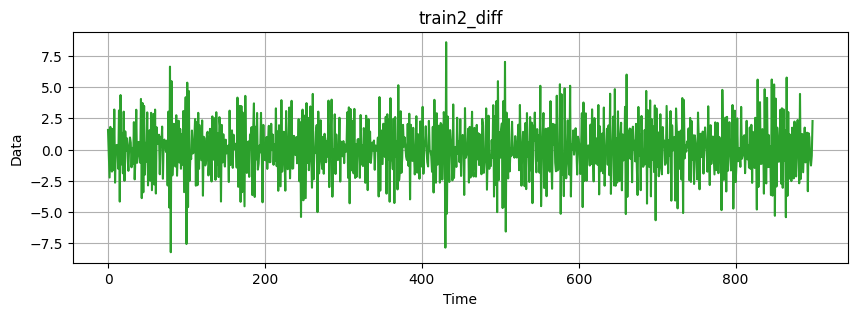

In [21]:
train2_diff = np.diff(train_ts2)

fig, ax = plt.subplots(1, 1, figsize=(10, 3))
ax.plot(np.arange(len(train2_diff)), train2_diff, color='tab:green')
ax.set_xlabel("Time")
ax.set_ylabel("Data")
plt.title("train2_diff");
plt.grid()

_, pvalue, _, _, _, _ = adfuller(train2_diff)
print(f"p-value: {pvalue:.3f}")

После дифференцирования ряд стал стационарным.

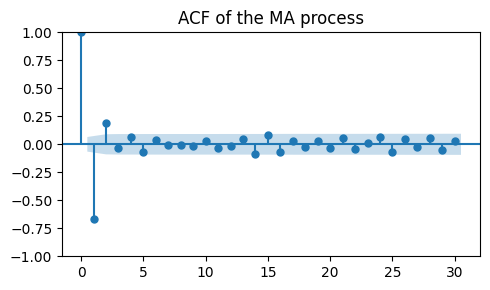

In [22]:
_, ax = plt.subplots(1, 1, figsize=(5, 3))
plot_acf(train2_diff, ax=ax, title="ACF of the MA process")
plt.tight_layout();

ACF показывает 2 значимых лага, будет построена модель MA(2).

In [23]:
from scipy.fft import fft

def fft_analysis(signal):
    slope, intercept = np.polyfit(np.arange(len(signal)), signal, 1)
    trend = np.arange(len(signal)) * slope + intercept
    detrended = signal - trend
    fft_values = fft(detrended)
    frequencies = np.fft.fftfreq(len(fft_values))
    positive_frequencies = frequencies[frequencies > 0]
    magnitudes = np.abs(fft_values)[frequencies > 0]
    dominant_frequency = positive_frequencies[np.argmax(magnitudes)]
    print(f"Dominant Frequency: {dominant_frequency:.3f}")
    dominant_period = 1 / dominant_frequency
    print(f"Dominant Period: {dominant_period:.2f} time units")
    return dominant_period, positive_frequencies, magnitudes

period, _, _ =fft_analysis(arma_ts2)
print(f"Period: {np.round(period)}")

Dominant Frequency: 0.042
Dominant Period: 23.81 time units
Period: 24.0


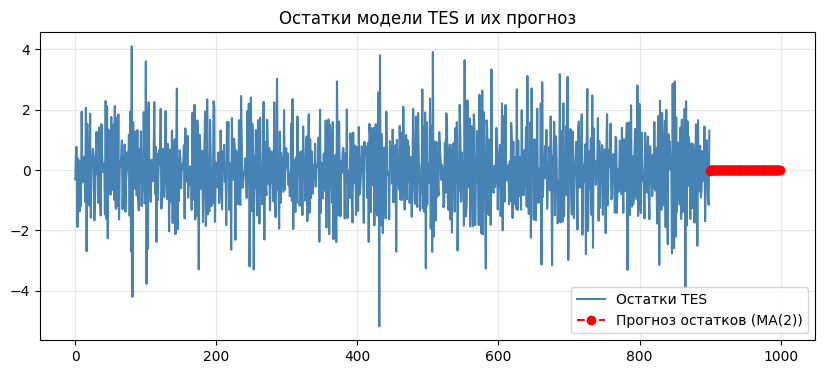

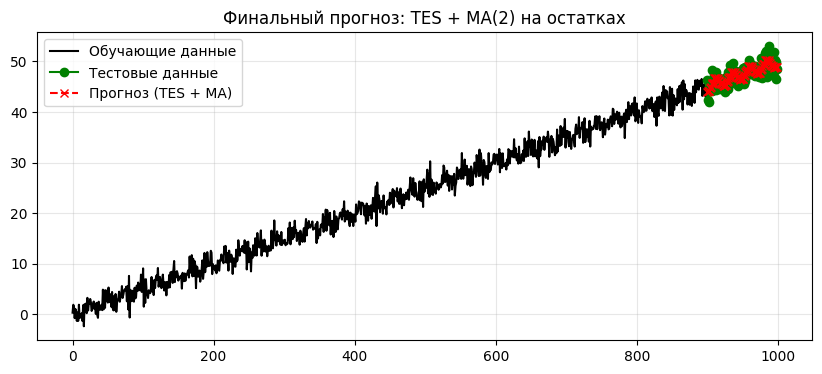

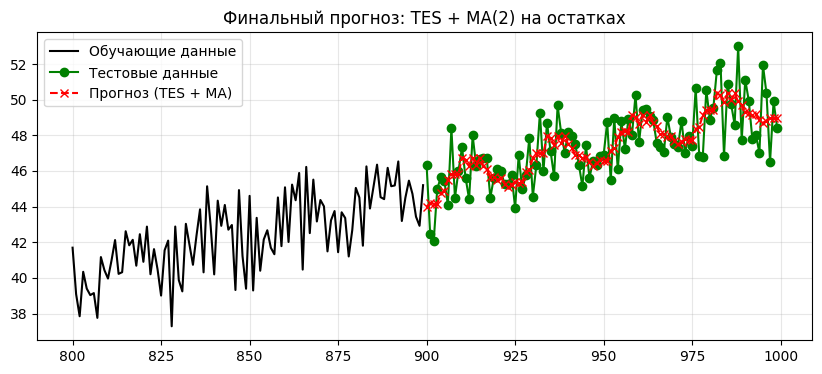

MSE of differencing: 17.26
MSE of TES:          1.69

 Подход на основе TES даёт более точный прогноз!


In [24]:
n2_test = 100

# подгонка TES к обучающим данным
tes = ExponentialSmoothing(
  train_ts2,
  trend='add',
  seasonal='add',
  seasonal_periods=24 # данный период был рассчитан методом
  ).fit()

# остатки
tes_fitted = tes.fittedvalues
tes_resid = train_ts2 - tes_fitted

# модель MA(2) на остатках
ma_model = ARIMA(tes_resid, order=(0, 0, 2))
ma_fit = ma_model.fit()
resid_preds = ma_fit.forecast(steps=n2_test)

# прогноз TES: тренд + сезонность
tes_pred = tes.forecast(steps=n2_test)

# финальный прогноз: TES + MA(остатки)
final_preds_tes = tes_pred + resid_preds

# подход на основе дифференцирования (для сравнения)
diff_train = np.diff(train_ts2)
ma_diff_model = ARIMA(diff_train, order=(0, 0, 2), trend='n').fit()
diff_forecast = ma_diff_model.forecast(steps=n2_test)

# реконструкция уровня (без дрейфа)
reintegrated = np.empty(n2_test)
current = train_ts2[-1]
for i in range(n2_test):
  current = current + diff_forecast[i]
  reintegrated[i] = current

# визуализация остатков
plt.figure(figsize=(10, 4))
plt.plot(mytime2_train, tes_resid, label='Остатки TES', color='steelblue')
plt.plot(mytime2_test, resid_preds, 'ro--', label='Прогноз остатков (MA(2))')
plt.title('Остатки модели TES и их прогноз')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# финальный прогноз (TES + AR)
plt.figure(figsize=(10, 4))
plt.plot(mytime2_train, train_ts2, label='Обучающие данные', color='black')
plt.plot(mytime2_test, test_ts2, 'o-', label='Тестовые данные', color='green')
plt.plot(mytime2_test, final_preds_tes, 'x--', label='Прогноз (TES + MA)', color='red')
plt.title('Финальный прогноз: TES + MA(2) на остатках')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# финальный прогноз (TES + AR)
plt.figure(figsize=(10, 4))
plt.plot(mytime2_train[800:], train_ts2[800:], label='Обучающие данные', color='black')
plt.plot(mytime2_test, test_ts2, 'o-', label='Тестовые данные', color='green')
plt.plot(mytime2_test, final_preds_tes, 'x--', label='Прогноз (TES + MA)', color='red')
plt.title('Финальный прогноз: TES + MA(2) на остатках')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# расчет MSE
mse_differencing = mean_squared_error(test_ts2, reintegrated)
mse_tes = mean_squared_error(test_ts2, final_preds_tes)

print(f"MSE of differencing: {mse_differencing:.2f}")
print(f"MSE of TES:          {mse_tes:.2f}")

if mse_tes < mse_differencing:
    print("\n Подход на основе TES даёт более точный прогноз!")

Финальный прогноз не очень хорошо повторил тестовые данные, ошибка MSE небольшая, наблюдается больший размах в тестовых данных (хотя тренд и сезонность учтены). Модель скользящего среднего подобрана верно.